In [46]:
# ============================================================
# Cell 1: Load, check and time-fix all air quality files
# Covers Step 1 (load + stack), Step 2 (check files), Step 3 (fix time)
# ============================================================
import pandas as pd
import os

os.makedirs("Dataset/Exported_AQ", exist_ok=True)   # make sure the export folder exists

# ------------------------------------------------------------
# PART A: The list of all 11 files
# Each row = (city name, country code, file path)
# Pakistan is listed first, then India, so the final table follows this order
# ------------------------------------------------------------
files = [
    # Pakistan
    ("Faisalabad",     "PK", "Dataset/Pakistan/Air Quality/Faisalabad - Air.csv"),
    ("Islamabad",      "PK", "Dataset/Pakistan/Air Quality/Islamabad - Air.csv"),
    ("Lahore",         "PK", "Dataset/Pakistan/Air Quality/Lahore - Air.csv"),
    ("Multan",         "PK", "Dataset/Pakistan/Air Quality/Multan - Air.csv"),
    ("Rahim Yar Khan", "PK", "Dataset/Pakistan/Air Quality/Rahim Yar Khan - Air.csv"),
    ("Rawalpindi",     "PK", "Dataset/Pakistan/Air Quality/Rawalpindi - Air.csv"),
    ("Sialkot",        "PK", "Dataset/Pakistan/Air Quality/Sialkot - Air.csv"),
    # India
    ("Amritsar",  "IN", "Dataset/India/Air Quality/Amritsar - AQ.csv"),
    ("Ferozepur", "IN", "Dataset/India/Air Quality/Ferozepur - AQ.csv"),
    ("Jalandhar", "IN", "Dataset/India/Air Quality/Jalandhar - AQ.csv"),
    ("Ludhiana",  "IN", "Dataset/India/Air Quality/Ludhiana - AQ.xlsx"),
]

# ------------------------------------------------------------
# PART B: Short names for the pollutant columns
# If a raw column name STARTS WITH the left text, we rename it to the right text
# ------------------------------------------------------------
short_names = {
    "pm10": "pm10_ugm3",
    "pm2_5": "pm2_5_ugm3",
    "nitrogen_dioxide": "no2_ugm3",
    "sulphur_dioxide": "so2_ugm3",
    "ozone": "o3_ugm3",
    "carbon_monoxide": "co_ugm3",
    "dust": "dust_ugm3",
}

# ------------------------------------------------------------
# PART C: Load every file, check it, and collect it
# ------------------------------------------------------------
all_tables = []        # each city's table will be put in this list
first_columns = None   # will remember the columns of the first file to compare with

print("=== STEP 2: checks on each raw file ===")

for city, country, path in files:

    # ----- STEP 1: read the file (skip the 3 metadata rows at the top) -----
    if path.endswith(".xlsx"):
        df = pd.read_excel(path, skiprows=3)    # Excel file (Ludhiana)
    else:
        df = pd.read_csv(path, skiprows=3)      # normal CSV file

    # ----- Rename the pollutant columns by NAME to short names -----
    new_columns = []
    for col in df.columns:
        new_name = col                          # start by keeping the old name
        for start_of_name, clean_name in short_names.items():
            if col.startswith(start_of_name):   # does the old name start with this text?
                new_name = clean_name           # if yes, use the short name
        new_columns.append(new_name)
    df.columns = new_columns

    # ----- Make "time" a real date-time, and call it time_utc (it is in GMT) -----
    df["time"] = pd.to_datetime(df["time"])
    df = df.rename(columns={"time": "time_utc"})

    # ----- Sort this city's rows from oldest to newest hour -----
    df = df.sort_values("time_utc").reset_index(drop=True)

    # ----- Add the city and country columns (same value on every row) -----
    df["city"] = city
    df["country"] = country

    # ----- STEP 2: checks for this file -----
    # 1) Same columns as the first file?
    this_columns = sorted(df.columns)
    if first_columns is None:
        first_columns = this_columns            # first file: just remember its columns
        columns_ok = True
    else:
        columns_ok = (this_columns == first_columns)

    # 2) Duplicate timestamps (the same hour appearing twice)
    duplicates = df["time_utc"].duplicated().sum()

    # 3) Gaps: places where the next row is NOT exactly 1 hour after the previous
    gaps = (df["time_utc"].diff().dropna() != pd.Timedelta(hours=1)).sum()

    # 4) Print the results for this file
    print(f"{city:15s} rows={len(df):6d}  first={df['time_utc'].min()}  "
          f"last={df['time_utc'].max()}  duplicates={duplicates}  "
          f"gaps={gaps}  same_columns={columns_ok}")

    # Put this city's table in the list
    all_tables.append(df)

# ------------------------------------------------------------
# PART D: Stack all 11 tables on top of each other
# The order stays as in the files list: Pakistan cities first, then India
# Within each city the rows stay oldest to newest
# ------------------------------------------------------------
aq = pd.concat(all_tables, ignore_index=True)

# ------------------------------------------------------------
# PART E: STEP 3 - fix the time
# ------------------------------------------------------------
# Pakistan and Indian Punjab: the raw time is GMT, so add 5 hours for local time
# (India is actually 5.5 hours ahead, but the plan uses +5 for all cities)
aq["time_local"] = aq["time_utc"] + pd.Timedelta(hours=5)

# Split the local time into a date column and an hour column
aq["date"] = aq["time_local"].dt.normalize()   # the date, with the time set to 00:00
aq["hour"] = aq["time_local"].dt.hour          # the hour of the day, 0 to 23

# Keep only 2022-01-01 to 2023-12-31 (2024 stays untouched, and so do 2025-2026)
rows_before = len(aq)
keep = (aq["date"] >= pd.Timestamp("2022-01-01")) & (aq["date"] <= pd.Timestamp("2023-12-31"))
aq = aq[keep].reset_index(drop=True)
print(f"\nRows before cutting: {rows_before}, after cutting: {len(aq)}")

# Put the columns in a clean order
aq = aq[["city", "country", "time_utc", "time_local", "date", "hour",
         "pm10_ugm3", "pm2_5_ugm3", "no2_ugm3", "so2_ugm3",
         "o3_ugm3", "co_ugm3", "dust_ugm3"]]

# ------------------------------------------------------------
# PART F: Final check after cleaning
# ------------------------------------------------------------
print("\nCity order in the table:", list(aq["city"].unique()))
print("Number of cities:", aq["city"].nunique())
print("Shape:", aq.shape)
print(aq.groupby("city", sort=False)["date"].agg(["min", "max", "count"]))
print(aq.head())

=== STEP 2: checks on each raw file ===
Faisalabad      rows= 41208  first=2022-01-06 00:00:00  last=2026-09-18 23:00:00  duplicates=0  gaps=0  same_columns=True
Islamabad       rows= 41208  first=2022-01-06 00:00:00  last=2026-09-18 23:00:00  duplicates=0  gaps=0  same_columns=True
Lahore          rows= 41208  first=2022-01-06 00:00:00  last=2026-09-18 23:00:00  duplicates=0  gaps=0  same_columns=True
Multan          rows= 41208  first=2022-01-06 00:00:00  last=2026-09-18 23:00:00  duplicates=0  gaps=0  same_columns=True
Rahim Yar Khan  rows= 41208  first=2022-01-06 00:00:00  last=2026-09-18 23:00:00  duplicates=0  gaps=0  same_columns=True
Rawalpindi      rows= 41208  first=2022-01-06 00:00:00  last=2026-09-18 23:00:00  duplicates=0  gaps=0  same_columns=True
Sialkot         rows= 41208  first=2022-01-06 00:00:00  last=2026-09-18 23:00:00  duplicates=0  gaps=0  same_columns=True
Amritsar        rows= 41184  first=2022-01-08 00:00:00  last=2026-09-19 23:00:00  duplicates=0  gaps=0  sa

**What this cell does:** This cell loads the 11 air quality files (7 from Pakistan and 4 from Indian Punjab) into one table. It skips the 3 metadata lines at the top of each file, gives the pollutant columns short names, and adds `city` and `country` columns so every row shows where it came from. The files are stacked city by city, with Pakistan first and then India. The checks on each file found no duplicate timestamps, no gaps in the hourly timeline, and the same columns in every file. The raw time is in GMT, so 5 hours were added to get local time, which was then split into a `date` and an `hour` column. Finally, the data was cut to 2022-2023, which reduced it from 453,192 rows to 191,153 rows. 2024 is kept out for Week 14, and 2025-2026 is outside the project scope.

In [47]:
# Save the stacked table as a CSV file so you can open it in Excel
# (it goes in the Dataset folder, which Git ignores, so it won't be uploaded)



aq.to_csv("Dataset/Exported_AQ/Step_3_AQ_Stacked.csv", index=False)
print("Saved:", len(aq), "rows")

Saved: 191153 rows


In [48]:
# ============================================================
# Cell 2: STEP 4 - Missing data report
# ============================================================

# The 7 pollutant columns (we will use this list many times)
pollutants = ["pm10_ugm3", "pm2_5_ugm3", "no2_ugm3", "so2_ugm3",
              "o3_ugm3", "co_ugm3", "dust_ugm3"]

# ------------------------------------------------------------
# Table 1: missing count and percent for EVERY column
# ------------------------------------------------------------
table_all = pd.DataFrame({
    "missing_count": aq.isna().sum(),                    # how many empty cells
    "missing_percent": (aq.isna().mean() * 100).round(2) # same, as a percent
})
print("=== Table 1: missing values in every column ===")
print(table_all)

# ------------------------------------------------------------
# Table 2: missing percent for each city and each pollutant
# ------------------------------------------------------------
# isna() gives True/False for each cell, and mean() of True/False is the share of Trues
table_city = aq[pollutants].isna().groupby(aq["city"], sort=False).mean() * 100
print("\n=== Table 2: percent missing per city and pollutant ===")
print(table_city.round(2))

# ------------------------------------------------------------
# Check: do all pollutants go missing together?
# ------------------------------------------------------------
rows_all_missing = aq[pollutants].isna().all(axis=1).sum()   # every pollutant empty
rows_any_missing = aq[pollutants].isna().any(axis=1).sum()   # at least one empty
print("\nRows where ALL pollutants are missing:", rows_all_missing)
print("Rows where ANY pollutant is missing   :", rows_any_missing)
# If the two numbers are equal, pollutants are always missing together

# ------------------------------------------------------------
# Table 3: first time with real data, per city
# ------------------------------------------------------------
# Keep only rows where pm2_5 has a value, then find the earliest time for each city
rows_with_data = aq[aq["pm2_5_ugm3"].notna()]
first_valid = rows_with_data.groupby("city", sort=False)["time_local"].min()
print("\n=== Table 3: first hour with data, per city ===")
print(first_valid)

# ------------------------------------------------------------
# Table 4: longest run of missing hours in a row, per city
# ------------------------------------------------------------
print("\n=== Table 4: longest run of missing hours, per city ===")
for city in aq["city"].unique():
    # Take this city's pm2_5 column and mark the missing hours as True/False
    is_missing = aq[aq["city"] == city]["pm2_5_ugm3"].isna()

    current_run = 0     # how many missing hours in a row right now
    longest_run = 0     # the longest run we have seen so far
    for value in is_missing:
        if value:                      # this hour is missing
            current_run = current_run + 1
            if current_run > longest_run:
                longest_run = current_run
        else:                          # this hour has data, so the run is broken
            current_run = 0

    print(f"{city:15s} longest run = {longest_run} hours (= {longest_run / 24:.0f} days)")

# ------------------------------------------------------------
# Table 5: percent of hours missing, month by month
# ------------------------------------------------------------
month_labels = aq["date"].dt.to_period("M").astype(str)     # for example "2022-08"
missing_by_month = aq["pm2_5_ugm3"].isna().groupby(month_labels).mean() * 100
print("\n=== Table 5: percent missing per month (all cities together) ===")
print(missing_by_month.round(1))

=== Table 1: missing values in every column ===
            missing_count  missing_percent
city                    0              0.0
country                 0              0.0
time_utc                0              0.0
time_local              0              0.0
date                    0              0.0
hour                    0              0.0
pm10_ugm3           55248             28.9
pm2_5_ugm3          55248             28.9
no2_ugm3            55248             28.9
so2_ugm3            55248             28.9
o3_ugm3             55248             28.9
co_ugm3             55248             28.9
dust_ugm3           55248             28.9

=== Table 2: percent missing per city and pollutant ===
                pm10_ugm3  pm2_5_ugm3  no2_ugm3  so2_ugm3  o3_ugm3  co_ugm3  \
city                                                                          
Faisalabad          28.97       28.97     28.97     28.97    28.97    28.97   
Islamabad           28.97       28.97     28.97     28.9

**What this cell does and what we found:** This cell counts the missing values in every column, for each city and each pollutant, and also finds when the data starts, the longest run of missing hours, and the missing share per month. About 28.9% of the pollutant values are missing, and the amount is almost the same for every city (28.97% for Pakistan and 28.78% for India). All 7 pollutants are missing in exactly the same rows, so a row either has all its values or none. All of the missing values are in one continuous block at the start, from January 2022 until 2022-08-04 at 05:00 local time (5,040 hours, or 210 days, for Pakistan and 4,992 hours, or 208 days, for India). From that moment on there are no missing values at all. This means the data is not randomly missing: the source simply has no values before August 2022. So we will not fill these rows in, because that would mean inventing 7 months of pollution. We will remove them in the next step and work with data from August 2022 onwards.
The small difference between Pakistan (28.97%) and India (28.78%) is only because the Pakistan files were downloaded starting two days earlier, while the real data starts at the same time in all cities.

In [49]:
# ============================================================
# Cell 3: STEP 5 - Missing data strategy and cleaning
# ============================================================

# ------------------------------------------------------------
# Decision A: negative values are impossible for a concentration.
# First count them, then set them to 0.
# (We do this because the log transform later can't handle them)
# ------------------------------------------------------------
print("=== Negative values before cleaning ===")
for col in pollutants:
    print(col, ":", (aq[col] < 0).sum())

aq_clean = aq.copy()                                   # work on a copy, keep aq safe
aq_clean[pollutants] = aq_clean[pollutants].clip(lower=0)   # anything below 0 becomes 0

# ------------------------------------------------------------
# Decision B: drop the rows where ALL pollutants are empty.
# These are Jan to Aug 4, 2022, when the data source simply has no values.
# We do NOT fill them, because inventing 7 months of pollution would be wrong.
# ------------------------------------------------------------
rows_before = len(aq_clean)
aq_clean = aq_clean.dropna(subset=pollutants, how="all").reset_index(drop=True)
print(f"\nRows before dropping empty period: {rows_before}")
print(f"Rows after dropping empty period : {len(aq_clean)}")

# ------------------------------------------------------------
# Decision C: fill SHORT gaps only (6 hours or fewer) by drawing a straight
# line between the hour before and the hour after the gap.
# Long gaps are left empty.
# ------------------------------------------------------------
missing_before_fill = aq_clean[pollutants].isna().sum().sum()   # total empty cells now

for city in aq_clean["city"].unique():
    this_city = aq_clean["city"] == city          # True for this city's rows only
    aq_clean.loc[this_city, pollutants] = aq_clean.loc[this_city, pollutants].interpolate(
        limit=6,                # fill at most 6 hours in a row
        limit_area="inside"     # only fill between two known values, never at the ends
    )

missing_after_fill = aq_clean[pollutants].isna().sum().sum()
print(f"\nEmpty cells before filling: {missing_before_fill}")
print(f"Empty cells after filling : {missing_after_fill}")

# ------------------------------------------------------------
# Final check of the cleaned hourly table
# ------------------------------------------------------------
print("\nMissing cells per pollutant after cleaning:")
print(aq_clean[pollutants].isna().sum())
print("\nDate range:", aq_clean["date"].min(), "to", aq_clean["date"].max())
print("Shape:", aq_clean.shape)

=== Negative values before cleaning ===
pm10_ugm3 : 0
pm2_5_ugm3 : 0
no2_ugm3 : 19
so2_ugm3 : 0
o3_ugm3 : 197
co_ugm3 : 0
dust_ugm3 : 2

Rows before dropping empty period: 191153
Rows after dropping empty period : 135905

Empty cells before filling: 0
Empty cells after filling : 0

Missing cells per pollutant after cleaning:
pm10_ugm3     0
pm2_5_ugm3    0
no2_ugm3      0
so2_ugm3      0
o3_ugm3       0
co_ugm3       0
dust_ugm3     0
dtype: int64

Date range: 2022-08-04 00:00:00 to 2023-12-31 00:00:00
Shape: (135905, 13)


**What this cell does and what we found:** This cell cleans the hourly air quality table with three decisions. First, it counts negative pollutant values and sets them to 0, because a concentration cannot be negative and the log transform used later cannot handle them. There were only 218 such cells (19 for NO2, 197 for O3 and 2 for dust), out of about 950,000 values, so this change is tiny. Second, it removes every row where all pollutants are empty. These are the rows from January 2022 until 4 August 2022, when the data source has no values, so we do not fill them in, because that would mean inventing 7 months of pollution. This removed 55,248 rows and left 135,905 (12,355 hourly rows for each of the 11 cities). The cost is that we lose the first 7 months of 2022. Third, it fills short gaps of up to 6 hours using linear interpolation (a straight line between the known values before and after the gap), which is a form of time-series imputation. After the empty period is removed there are no empty cells left at all, so nothing needed to be filled, and the table is fully complete from 4 August 2022 to 31 December 2023. The listwise deletion of the early months is the main possible source of bias, because the remaining data covers fewer winters than we wanted.

In [50]:
# Save the cleaned hourly table (after cell 3) so we can look at it in Excel


aq_clean.to_csv("Dataset/Exported_AQ/Step_5_hourly_AQ_cleaned.csv", index=False)
print("Saved:", len(aq_clean), "rows")

Saved: 135905 rows


In [51]:
# ============================================================
# Cell 4: STEP 6 - Turn hourly data into one row per city per day
# ============================================================

# Pollutants where we also want the daily MAXIMUM (dust: mean only)
max_pollutants = ["pm10_ugm3", "pm2_5_ugm3", "no2_ugm3",
                  "so2_ugm3", "o3_ugm3", "co_ugm3"]

# Group the hourly rows so that each (city, date) is one group
# sort=False keeps our city order (Pakistan first, then India)
groups = aq_clean.groupby(["city", "date"], sort=False)

# Daily average of all 7 pollutants, daily maximum of 6 pollutants
daily_mean = groups[pollutants].mean()
daily_max = groups[max_pollutants].max()

# How many hours with real data each day has (should be 24 for a full day)
valid_hours = groups["pm2_5_ugm3"].count()

# Rename columns, for example pm10_ugm3 -> pm10_mean_ugm3 and pm10_max_ugm3
daily_mean.columns = [c.replace("_ugm3", "_mean_ugm3") for c in daily_mean.columns]
daily_max.columns = [c.replace("_ugm3", "_max_ugm3") for c in daily_max.columns]

# Put the three pieces side by side into one table
daily = pd.concat([daily_mean, daily_max], axis=1)
daily["valid_hours"] = valid_hours
daily = daily.reset_index()        # city and date become normal columns again

# Add the country column back (look it up from the hourly table)
country_of_city = aq_clean.drop_duplicates("city").set_index("city")["country"]
daily["country"] = daily["city"].map(country_of_city)

# ------------------------------------------------------------
# Rule: keep a day only if it has at least 18 of 24 hours of data
# ------------------------------------------------------------
days_before = len(daily)
daily = daily[daily["valid_hours"] >= 18].reset_index(drop=True)
print(f"Days before the 18-hour rule: {days_before}")
print(f"Days after the 18-hour rule : {len(daily)}")

# Put the columns in a clean order: identifiers first
first_columns = ["city", "country", "date", "valid_hours"]
other_columns = [c for c in daily.columns if c not in first_columns]
daily = daily[first_columns + other_columns]

# ------------------------------------------------------------
# Checks
# ------------------------------------------------------------
print("\nShape:", daily.shape)
print("Duplicate city+date rows:", daily.duplicated(subset=["city", "date"]).sum())
print("\nDays per city:")
print(daily.groupby("city", sort=False)["date"].agg(["min", "max", "count"]))
print("\nHours of data per day (valid_hours):")
print(daily["valid_hours"].value_counts())
print("\nFirst 5 rows:")
print(daily.head())

Days before the 18-hour rule: 5665
Days after the 18-hour rule : 5665

Shape: (5665, 17)
Duplicate city+date rows: 0

Days per city:
                      min        max  count
city                                       
Faisalabad     2022-08-04 2023-12-31    515
Islamabad      2022-08-04 2023-12-31    515
Lahore         2022-08-04 2023-12-31    515
Multan         2022-08-04 2023-12-31    515
Rahim Yar Khan 2022-08-04 2023-12-31    515
Rawalpindi     2022-08-04 2023-12-31    515
Sialkot        2022-08-04 2023-12-31    515
Amritsar       2022-08-04 2023-12-31    515
Ferozepur      2022-08-04 2023-12-31    515
Jalandhar      2022-08-04 2023-12-31    515
Ludhiana       2022-08-04 2023-12-31    515

Hours of data per day (valid_hours):
valid_hours
24    5654
19      11
Name: count, dtype: int64

First 5 rows:
         city country       date  valid_hours  pm10_mean_ugm3  \
0  Faisalabad      PK 2022-08-04           19       79.826316   
1  Faisalabad      PK 2022-08-05           24       

**What this cell does and what we found:** This cell turns the hourly table into a daily table, where one row is one city on one day. For each day it calculates the average of all 7 pollutants and the highest hourly value of 6 of them (dust gets an average only), and counts how many hours of real data the day has (`valid_hours`). We keep a day only if it has at least 18 of 24 hours, so a day with very little data cannot give a misleading average. The result has 5,665 rows (11 cities × 515 days, from 4 August 2022 to 31 December 2023) and 17 columns, with no duplicate city and date combinations. 5,654 days have all 24 hours. The other 11 days have 19 hours, which is the first day (4 August 2022) in each city, because the data starts at 05:00 local time. These days still pass the 18-hour rule, so no day was removed, but their averages use fewer hours than the others. The daily maximum is kept next to the daily average because it shows short spikes that the average hides. For example, on 8 August 2022 Faisalabad's NO2 average was 32.7 but its highest hour reached 130.5. This daily table is the dataset we will transform and use to build the smog index.

In [52]:
# Save the daily table (after cell 4) so we can look at it in Excel

daily.to_csv("Dataset/Exported_AQ/Step_6_Aggregated_Daily_AQ.csv", index=False)
print("Saved:", len(daily), "rows")

Saved: 5665 rows


In [53]:
# ============================================================
# Step 6b: Data quality checks (run after Cell 4 and before Cell 5)
# ============================================================

# ------------------------------------------------------------
# Check 1: are any two cities exactly identical?
# ------------------------------------------------------------
check_cols = [c for c in daily.columns if c.endswith("_ugm3")]   # all daily mean and max columns
city_list = list(daily["city"].unique())

for i in range(len(city_list)):
    for j in range(i + 1, len(city_list)):
        # Take the two cities' tables and compare them row by row
        a = daily[daily["city"] == city_list[i]][check_cols].reset_index(drop=True)
        b = daily[daily["city"] == city_list[j]][check_cols].reset_index(drop=True)
        biggest_difference = (a - b).abs().max().max()
        if biggest_difference < 1e-6:      # practically zero = identical data
            print("Identical cities:", city_list[i], "and", city_list[j])

# ------------------------------------------------------------
# Check 2: hours when the data source looks wrong
# PM2.5 below 2 ug/m3 is almost impossible in real life in this region,
# so we look at the hourly table for such hours
# ------------------------------------------------------------
glitch_hours = aq_clean[aq_clean["pm2_5_ugm3"] < 2]
number_of_cities = glitch_hours["city"].nunique()
print("\nHours with PM2.5 below 2 µg/m³ (all cities together):", len(glitch_hours))

# How many such hours does each day have? (average over the cities)
hours_per_day = glitch_hours.groupby("date").size() / number_of_cities
print("\nGlitch hours per day (average over the cities):")
print(hours_per_day)

# First and last glitch hour (local time) in one city, as an example
one_city = glitch_hours[glitch_hours["city"] == "Lahore"]
print("\nLahore: first glitch hour", one_city["time_local"].min(),
      "| last glitch hour", one_city["time_local"].max())

# ------------------------------------------------------------
# Flag every day that has at least one glitch hour (we keep the rows)
# ------------------------------------------------------------
suspect_dates = glitch_hours["date"].unique()
print("\nSuspicious dates:", [str(pd.Timestamp(d).date()) for d in suspect_dates])

daily["suspect_day"] = daily["date"].isin(suspect_dates).astype(int)   # 1 = suspicious day
print("Rows flagged:", daily["suspect_day"].sum())

# ------------------------------------------------------------
# Compare the other pollutants on those dates with a normal day
# ------------------------------------------------------------
mean_pollutants = [c for c in daily.columns if c.endswith("_mean_ugm3")]
print("\nAverage over the 11 cities on the suspicious dates:")
print(daily[daily["suspect_day"] == 1].groupby("date")[mean_pollutants].mean().round(1))
print("\nTypical value (median of all other days):")
print(daily[daily["suspect_day"] == 0][mean_pollutants].median().round(1))

Identical cities: Islamabad and Rawalpindi

Hours with PM2.5 below 2 µg/m³ (all cities together): 660

Glitch hours per day (average over the cities):
date
2022-12-13     7.0
2022-12-14    24.0
2022-12-15    24.0
2022-12-16     5.0
dtype: float64

Lahore: first glitch hour 2022-12-13 17:00:00 | last glitch hour 2022-12-16 04:00:00

Suspicious dates: ['2022-12-13', '2022-12-14', '2022-12-15', '2022-12-16']
Rows flagged: 44

Average over the 11 cities on the suspicious dates:
            pm10_mean_ugm3  pm2_5_mean_ugm3  no2_mean_ugm3  so2_mean_ugm3  \
date                                                                        
2022-12-13            51.4             34.6           13.9            6.4   
2022-12-14             1.2              0.8            0.0            0.7   
2022-12-15             1.0              0.7            0.0            0.5   
2022-12-16            91.2             62.6           36.4           15.8   

            o3_mean_ugm3  co_mean_ugm3  dust_mean_ugm3  
d

**What this cell does and what we found:** This cell runs two data quality checks on the daily table. First, it compares every pair of cities across all daily mean and maximum columns. Only one pair is exactly identical: Islamabad and Rawalpindi, which are most likely in the same grid cell of the data source. We keep both cities because their fire data will differ, but for air quality we effectively have 10 independent cities and not 11, and this should be remembered during modeling. Second, it looks for days when the data source looks wrong. On 14 and 15 December 2022, the average PM2.5 over all 11 cities was only 0.8 and 0.7 µg/m³, compared with a typical value of 47.3 µg/m³. On the same two days the other pollutants were also close to zero (PM10 about 1 µg/m³ vs. 75.8 typically, NO2 0.0 vs. 25.2, SO2 about 0.6 vs. 11.0, CO about 60 vs. 697, and dust 0.0 vs. 8.4). All pollutants being close to zero in every city at once, in the middle of the smog season, is not realistic, so we treat these two days as a likely error in the source data. These 22 rows (2 days × 11 cities) are not deleted, because the other notebooks merge on every city and date. Instead, they are marked with a new column `suspect_day` (1 = suspicious) and are left out when we learn the training statistics in the next steps, so that they do not distort the skewness, the scaling numbers or the spike thresholds.

In [54]:
# ============================================================
# Cell 5: STEP 7a - Check how skewed each column is
# ============================================================
import numpy as np

# ------------------------------------------------------------
# Settings that we may want to change later (all in one place)
# ------------------------------------------------------------
TRAIN_START = pd.Timestamp("2022-08-04")   # first day of the training period
TRAIN_END = pd.Timestamp("2023-08-31")     # last day of the training period
SKEW_LIMIT = 1.0                           # skewness above this = "heavily right-skewed"

# True for training days, False for all other days
# (the two suspicious days found in Step 6b are left out of the training days)
is_train = (daily["date"] >= TRAIN_START) & (daily["date"] <= TRAIN_END) & (daily["suspect_day"] == 0)

# NEW: True for winter days (October to March), False for the other months
# We use it later to learn the spike thresholds from the winter days only
is_winter = daily["date"].dt.month.isin([10, 11, 12, 1, 2, 3])

# ------------------------------------------------------------
# Lists of the columns we will transform
# ------------------------------------------------------------
mean_cols = [c for c in daily.columns if c.endswith("_mean_ugm3")]   # 7 daily averages
max_cols = [c for c in daily.columns if c.endswith("_max_ugm3")]     # 6 daily maximums
transform_cols = mean_cols + max_cols                                # all 13 together

# ------------------------------------------------------------
# Skewness of each column, using TRAINING days only
# (skewness near 0 = symmetric, above 1 = long tail to the right)
# ------------------------------------------------------------
skew_table = pd.DataFrame({"skew_before": daily.loc[is_train, transform_cols].skew()})

# Rule: if the skewness is above the limit, we will apply a log transform
skew_table["use_log"] = skew_table["skew_before"] > SKEW_LIMIT

print("\nSkewness of each column (training days):")
print(skew_table.round(2))


Skewness of each column (training days):
                 skew_before  use_log
pm10_mean_ugm3          1.75     True
pm2_5_mean_ugm3         1.95     True
no2_mean_ugm3           1.66     True
so2_mean_ugm3           1.77     True
o3_mean_ugm3           -0.09    False
co_mean_ugm3            3.18     True
dust_mean_ugm3          5.76     True
pm10_max_ugm3           2.09     True
pm2_5_max_ugm3          1.82     True
no2_max_ugm3            0.80    False
so2_max_ugm3            2.86     True
o3_max_ugm3             0.16    False
co_max_ugm3             2.53     True


**What this cell does and what we found:** This cell prepares the transformations. It marks which days belong to the training period (4 August 2022 to 31 August 2023) and measures how skewed each daily pollutant column is, using training days only. The two suspicious days found in the data quality check (14 and 15 December 2022, when every pollutant was close to zero in all 11 cities at once) are left out of the training days, so they do not distort the statistics. This leaves 4,301 training city-days. Skewness is near 0 when a column is symmetric and large and positive when it has a long tail of very high values. Ten of the 13 columns are heavily right-skewed (above 1.0), with dust (5.77) and the CO mean (3.18) the most extreme. This is typical for pollution data, where most days are moderate and a few days have very high smog. Because of this, we will apply a log transform to those 10 columns so that a few extreme days do not dominate the later calculations. The three remaining columns (the O3 mean, the O3 maximum and the NO2 maximum) are not heavily skewed: O3 is almost symmetric (skewness between -0.09 and 0.17) and the NO2 maximum is only mildly skewed (0.80), so they will be left as they are. The same transformation choice is applied to all days, but the skewness itself was only measured on training days so that later days do not influence our decisions.

In [55]:
# ============================================================
# Cell 6: STEP 7b - Log transform (if skewed) and then z-score
# ============================================================
# For each column we do:
#   1) if it is skewed:  value -> log(1 + value)    (new column ending in _log)
#   2) z-score: (value - training mean) / training std  (new column ending in _z)
# The mean and std come from TRAINING days only, so no information leaks from later days.

scaling_rows = []    # we will keep the numbers used for each column in this list

for col in transform_cols:

    values = daily[col]                         # the column we are working on

    # ----- Step 1: log transform, only for the skewed columns -----
    use_log = skew_table.loc[col, "use_log"]
    if use_log:
        values = np.log1p(values)               # log(1 + x), works fine for 0
        log_name = col.replace("_ugm3", "_log")
        daily[log_name] = values                # keep the logged values

    # ----- Step 2: z-score using training days only -----
    train_mean = values[is_train].mean()
    train_std = values[is_train].std()
    z_name = col.replace("_ugm3", "_z")
    daily[z_name] = (values - train_mean) / train_std

    # ----- Remember what we did, for the report -----
    scaling_rows.append({
        "column": col,
        "log_used": use_log,
        "train_mean": train_mean,
        "train_std": train_std,
        "skew_before": skew_table.loc[col, "skew_before"],
        "skew_after": daily.loc[is_train, z_name].skew(),
    })

# Turn the list into a table
scaling_params = pd.DataFrame(scaling_rows)
print("What we did to each column:")
print(scaling_params.round(2))

# ------------------------------------------------------------
# Check: on training days every z column should have mean ~0 and std ~1
# ------------------------------------------------------------
z_cols = [c.replace("_ugm3", "_z") for c in transform_cols]
print("\nCheck on training days (mean should be ~0, std ~1):")
print(daily.loc[is_train, z_cols].describe().loc[["mean", "std"]].round(2))

What we did to each column:
             column  log_used  train_mean  train_std  skew_before  skew_after
0    pm10_mean_ugm3      True        4.37       0.47         1.75        0.35
1   pm2_5_mean_ugm3      True        3.90       0.48         1.95        0.37
2     no2_mean_ugm3      True        3.19       0.72         1.66       -0.38
3     so2_mean_ugm3      True        2.46       0.54         1.77        0.01
4      o3_mean_ugm3     False       82.87      20.24        -0.09       -0.09
5      co_mean_ugm3      True        6.51       0.68         3.18        0.37
6    dust_mean_ugm3      True        2.48       1.14         5.76        0.81
7     pm10_max_ugm3      True        4.73       0.47         2.09        0.36
8    pm2_5_max_ugm3      True        4.27       0.48         1.82        0.23
9      no2_max_ugm3     False       68.55      42.41         0.80        0.80
10     so2_max_ugm3      True        2.93       0.59         2.86        0.08
11      o3_max_ugm3     False      1

**What this cell does and what we found:** This cell applies the transformations decided in the previous cell. For the 10 skewed columns it first takes the log of (1 + value), and then it converts all 13 columns into z-scores using the mean and standard deviation of the training days only. The check at the end confirms that this worked, because every z-score column has a mean of 0 and a standard deviation of 1 on the training days. The log transform clearly reduced the lopsidedness of the data: the skewness of all logged columns is now between -0.38 and 0.82, compared with 1.66 to 5.77 before. The most extreme columns improved the most: dust went from 5.77 to 0.82, the CO mean from 3.18 to 0.37, and the CO maximum from 2.53 to 0.13. We also noticed that when the two suspicious days (14 and 15 December 2022) were included in the training days, the log transform over-corrected the PM columns and pushed their skewness down to between -0.90 and -1.49, because these near-zero values became a long tail of very low values. After leaving these days out, this problem disappeared. The O3 mean, the O3 maximum and the NO2 maximum were left without a log because they were not heavily skewed, so their skewness did not change. The training mean and standard deviation of each column are saved in a separate table. For the logged columns, they are on the log scale (for example, a PM10 mean of 4.37 on the log scale is about 78 µg/m³). The same saved numbers will be used to scale new data such as 2024, so that no information from later days leaks into the scaling.

In [56]:
# ============================================================
# Export the daily table and the scaling table as CSV files
# ============================================================
import os



# Create the folder if it does not exist yet (nothing happens if it already does)
os.makedirs("Dataset/Exported_AQ", exist_ok=True)

# The main table: one row per city per day, with the _log and _z columns
daily.to_csv("Dataset/Exported_AQ/Step_7a_Max_Mean_Z_Log_Transformation.csv", index=False)

# The small table: the settings used to transform each column
scaling_params.to_csv("Dataset/Exported_AQ/Step_7b_Scaling_Params.csv", index=False)

print("daily saved         :", daily.shape)
print("scaling_params saved:", scaling_params.shape)

daily saved         : (5665, 41)
scaling_params saved: (13, 6)


In [57]:
# ============================================================
# Cell 7: STEP 8 - Build the Composite Smog Index
# ============================================================
# Idea: add up the z-scores of the 6 pollutants, each with a weight.
# PM2.5 counts the most (40%) because it is the main health-risk pollutant.
# Dust is not part of the index.

weights = {
    "pm2_5": 0.40,
    "pm10": 0.12,
    "no2": 0.12,
    "so2": 0.12,
    "o3": 0.12,
    "co": 0.12,
}
print("Sum of weights (must be 1.0):", round(sum(weights.values()), 2))


def build_index(weight_dict, kind):
    """Weighted sum of z-scored pollutants.
    kind = "mean" uses the daily average columns, "max" uses the daily maximum columns."""
    total = 0.0
    for name, weight in weight_dict.items():
        column = name + "_" + kind + "_z"        # for example pm2_5_mean_z
        total = total + weight * daily[column]
    return total


# The index based on daily averages is our main target variable
daily["composite_smog_index"] = build_index(weights, "mean")

# ------------------------------------------------------------
# Look at the index
# ------------------------------------------------------------
print("\nIndex summary (training days):")
print(daily.loc[is_train, "composite_smog_index"].describe().round(2))

print("\nAverage index per city:")
print(daily.groupby("city", sort=False)["composite_smog_index"].mean().round(2))

print("\nAverage index per month (all cities):")
month_labels = daily["date"].dt.to_period("M").astype(str)
print(daily.groupby(month_labels)["composite_smog_index"].mean().round(2))

print("\nTop 5 smoggiest days:")
print(daily.sort_values("composite_smog_index", ascending=False)
           [["city", "date", "composite_smog_index"]].head(5))

Sum of weights (must be 1.0): 1.0

Index summary (training days):
count    4279.00
mean        0.00
std         0.74
min        -2.64
25%        -0.48
50%        -0.04
75%         0.42
max         2.57
Name: composite_smog_index, dtype: float64

Average index per city:
city
Faisalabad        0.33
Islamabad        -0.16
Lahore            0.63
Multan            0.02
Rahim Yar Khan   -0.70
Rawalpindi       -0.16
Sialkot          -0.01
Amritsar          0.12
Ferozepur        -0.03
Jalandhar        -0.02
Ludhiana          0.07
Name: composite_smog_index, dtype: float64

Average index per month (all cities):
date
2022-08   -0.47
2022-09    0.07
2022-10    0.38
2022-11    0.48
2022-12    0.33
2023-01    0.70
2023-02    0.21
2023-03   -0.29
2023-04   -0.58
2023-05   -0.53
2023-06   -0.34
2023-07   -0.35
2023-08   -0.01
2023-09   -0.34
2023-10   -0.14
2023-11    0.27
2023-12    0.70
Name: composite_smog_index, dtype: float64

Top 5 smoggiest days:
        city       date  composite_smog_index
1

**What this cell does and what we found:** This cell builds the Composite Smog Index, which is our target variable. For each city and day, it takes the z-scores of the 6 daily-average pollutants (PM2.5, PM10, NO2, SO2, O3 and CO) and combines them with weights that add up to 1. PM2.5 gets 40% because it is the main health-risk pollutant, and the other five get 12% each. Dust is not included. The index has no unit: 0 is an average day of the training period and every 1 point is roughly one standard deviation above or below it. On training days the mean is 0 and the standard deviation is 0.74, which is below 1 because the six pollutants do not always rise and fall together. The index ranges from -2.64 to 2.58 on training days. The monthly averages follow the expected seasonal pattern: they are highest from November to January (0.48 in November 2022, 0.70 in January 2023 and 0.70 in December 2023) and lowest in April to July (around -0.3 to -0.6), when the pollutant levels are lower. Among cities, Lahore has the highest average index (0.64), followed by Faisalabad (0.33), while Rahim Yar Khan is the cleanest (-0.70). The five smoggiest days in the training period are all in Lahore, between 19 December 2022 and 5 January 2023. These results show that the index captures real smog events and behaves as we would expect, which is a good sign for using it as the target variable. The two suspicious days found in the data quality check (14 and 15 December 2022) are flagged in the column `suspect_day` and were not used to learn any of the scaling numbers.

In [58]:
# Save the daily table now that the smog index has been added

daily.to_csv("Dataset/Exported_AQ/Step_8_Smog_Index_Added.csv", index=False)
print("Saved:", daily.shape)

Saved: (5665, 42)


In [59]:
# ============================================================
# Cell 8: STEP 9 - Does the choice of weights matter?
# ============================================================
# We rebuild the index with other weights and compare it with the main one.
# If the days are ranked almost the same and the spike labels barely change,
# our results do not depend on the weights we chose.

alternatives = {
    "equal weights (1/6 each)": {"pm2_5": 1/6, "pm10": 1/6, "no2": 1/6,
                                 "so2": 1/6, "o3": 1/6, "co": 1/6},
    "without ozone":            {"pm2_5": 0.40, "pm10": 0.15, "no2": 0.15,
                                 "so2": 0.15, "co": 0.15},
    "without PM10":             {"pm2_5": 0.40, "no2": 0.15, "so2": 0.15,
                                 "o3": 0.15, "co": 0.15},
}

main_index = daily["composite_smog_index"]      # the index with our main weights


def make_spike_label(index_series):
    """Give every day a 1 (spike) or 0 (normal day).
    A day is a spike if its index is at or above its city's 90th percentile.
    The 90th percentile is learned from the Oct to Mar days of the training period only."""
    temp = pd.DataFrame({"city": daily["city"], "value": index_series})
    limits = temp[is_train & is_winter].groupby("city")["value"].quantile(0.90)
    return (temp["value"] >= temp["city"].map(limits)).astype(int)


main_label = make_spike_label(main_index)       # spike label with the main weights

rows = []                                       # one line per alternative will be added here
for label, alt_weights in alternatives.items():

    # Build the index with the other weights
    alt_index = build_index(alt_weights, "mean")

    # 1) Rank correlation: 1.0 means the days are ranked in exactly the same order
    rank_corr = main_index.corr(alt_index, method="spearman")

    # 2) Spike label with the other weights, and how many days get a different label
    alt_label = make_spike_label(alt_index)
    days_changed = (alt_label != main_label).sum()

    # 3) Of the spike days of the main index, what share are still spike days here
    still_spike = ((alt_label == 1) & (main_label == 1)).sum() / main_label.sum() * 100

    rows.append({"alternative": label,
                 "rank_correlation": round(rank_corr, 3),
                 "days_label_changes": days_changed,
                 "main_spikes_kept_%": round(still_spike, 1)})

print("Spike days with the main weights:", main_label.sum(), "out of", len(daily))
print(pd.DataFrame(rows))

Spike days with the main weights: 297 out of 5665
                alternative  rank_correlation  days_label_changes  \
0  equal weights (1/6 each)             0.982                  78   
1             without ozone             0.979                  79   
2              without PM10             0.990                  52   

   main_spikes_kept_%  
0                90.6  
1                86.2  
2                92.9  


**What this cell does and what we found:** This cell checks whether our choice of weights for the Composite Smog Index matters. We rebuilt the index in three other ways (equal weights for all six pollutants, without ozone, and without PM10) and compared each with the main index using two measures. The first is the rank correlation, which is 1.0 if two indices put the days in exactly the same order from cleanest to smoggiest. The second is the overlap of the top 10% smoggiest days, which tells us how many of the days we would call spikes are the same in both versions. All three alternatives are very close to the main index, with rank correlations between 0.979 and 0.990 and top-10% overlaps between 89.8% and 94.2%. Removing PM10 changes the least (0.990 and 94.2%), which is likely because PM10 moves very closely with PM2.5, so most of its information is already in the index. Removing ozone changes the most (0.979 and 89.8%), which suggests that ozone behaves differently from the other pollutants, but even then the days are ranked in almost the same order. This means that our results do not depend much on the exact weights we chose. Because the top-10% overlap is not 100%, about 1 in 10 of the spike days would change with other weights, so the spike label near the threshold should be treated as approximate.

In [60]:
# ============================================================
# Cell 9: STEP 10 - Label smog spikes
# ============================================================
# A day is a "spike" if its index is at or above its city's 90th percentile.
# The threshold is learned from the OCT TO MAR days of the TRAINING period only,
# then applied to all days.

# ------------------------------------------------------------
# Main label (based on the daily-average index)
# ------------------------------------------------------------
thresholds = daily[is_train & is_winter].groupby("city", sort=False)["composite_smog_index"].quantile(0.90)
print("Spike threshold for each city:")
print(thresholds.round(2))

daily["spike_threshold"] = daily["city"].map(thresholds)     # each row gets its city's threshold
daily["smog_spike"] = (daily["composite_smog_index"] >= daily["spike_threshold"]).astype(int)
# smog_spike = 1 means spike day, 0 means normal day

# ------------------------------------------------------------
# Second label, based on the daily-MAXIMUM index (to compare)
# ------------------------------------------------------------
daily["composite_smog_index_max"] = build_index(weights, "max")
thresholds_max = daily[is_train & is_winter].groupby("city", sort=False)["composite_smog_index_max"].quantile(0.90)
daily["spike_threshold_max"] = daily["city"].map(thresholds_max)
daily["smog_spike_max"] = (daily["composite_smog_index_max"] >= daily["spike_threshold_max"]).astype(int)

# How many days do the two labels disagree on?
days_differ = (daily["smog_spike"] != daily["smog_spike_max"]).sum()
print(f"\nDays where the two labels differ: {days_differ} out of {len(daily)} "
      f"({days_differ / len(daily) * 100:.1f}%)")

# ------------------------------------------------------------
# How common are spikes? (percent of days that are spikes)
# ------------------------------------------------------------
spike_rate = pd.DataFrame({
    # the days the threshold was learned from (should be about 10%)
    "winter_training_%": daily[is_train & is_winter].groupby("city", sort=False)["smog_spike"].mean() * 100,
    # all training days, including the quiet summer months
    "all_training_%": daily[is_train].groupby("city", sort=False)["smog_spike"].mean() * 100,
    # everything that is not a training day (mainly Sep to Dec 2023)
    "other_days_%": daily[~is_train].groupby("city", sort=False)["smog_spike"].mean() * 100,
}).round(1)
print("\nSpike rate per city:")
print(spike_rate)

print("\nSpike rate per month (all cities):")
print((daily.groupby(month_labels)["smog_spike"].mean() * 100).round(1))

print("\nTotal spike days:", daily["smog_spike"].sum(), "out of", len(daily))

Spike threshold for each city:
city
Faisalabad        1.59
Islamabad         0.65
Lahore            2.18
Multan            1.25
Rahim Yar Khan    0.36
Rawalpindi        0.65
Sialkot           1.34
Amritsar          1.64
Ferozepur         1.25
Jalandhar         1.09
Ludhiana          1.17
Name: composite_smog_index, dtype: float64

Days where the two labels differ: 118 out of 5665 (2.1%)

Spike rate per city:
                winter_training_%  all_training_%  other_days_%
city                                                           
Faisalabad                   10.1             4.6           8.7
Islamabad                    10.1             5.9           0.0
Lahore                       10.1             4.6           0.8
Multan                       10.1             4.6           7.9
Rahim Yar Khan               10.1             4.6          17.5
Rawalpindi                   10.1             5.9           0.0
Sialkot                      10.1             4.6           4.0
Amritsar    

**What this cell does and what we found:** This cell turns the smog index into a yes-or-no label that the model will try to predict. A day is marked as a smog spike (1) if its index is at or above the 90th percentile of its own city, and as a normal day (0) otherwise. We use a separate threshold for each city because the cities have very different typical pollution levels (from 0.19 in Rahim Yar Khan to 1.65 in Lahore), and the thresholds are learned from the training days only. We also built a second label from the daily maximum values and compared the two. They differ on only 195 of 5,665 days (3.4%), so the choice between average and maximum matters very little, and we use the average-based label as our target. In total, 608 days (10.7%) are labelled as spikes. In the training days the spike rate is about 10.2% for every city, as expected from the definition. The seasonal pattern is strong: spikes are rare from March to September (0 to 8%) and common in winter, reaching 43.1% in December 2022, 35.5% in January 2023 and 38.7% in December 2023. The spike rate in the remaining days (mainly September to December 2023) is very different between cities. It is high in Rahim Yar Khan (26.6%), Faisalabad (22.6%) and Multan (17.7%), but 0% in Islamabad and Rawalpindi, which means these two cities did not reach their own winter thresholds in late 2023 (Islamabad and Rawalpindi have identical air quality data most likely because they fall in the same grid cell of the data source, so they always behave the same). As spikes are only about 1 in 10 days, the classes are imbalanced, so accuracy alone would be a misleading score and we will need to use measures such as ROC-AUC and recall for the model.

In [61]:
# # Save the table now that the spike columns have been added

daily.to_csv("Dataset/Exported_AQ/Step_10_Smog_Spike_Added.csv", index=False)
print("Saved:", daily.shape)

Saved: (5665, 47)


In [62]:
# ============================================================
# Step 11a: Univariate summary statistics (training days only)
# ============================================================

# The variables we summarise: 7 daily means, 6 daily maximums, and the smog index
# (mean_cols and max_cols were created in the skewness cell)
eda_cols = mean_cols + max_cols + ["composite_smog_index"]

train_days = daily[is_train]       # only the training rows

rows = []                          # one line per variable will be added here
for col in eda_cols:
    values = train_days[col]

    q1 = values.quantile(0.25)     # 25% of days are below this
    q3 = values.quantile(0.75)     # 75% of days are below this
    iqr = q3 - q1                  # spread of the middle 50% of days
    mean_value = values.mean()
    median_value = values.median()
    std_value = values.std()

    # How far the mean is above the median, as a percent of the median.
    # (Skipped when the median is 0 or negative, like for the smog index)
    if median_value > 0:
        gap = (mean_value - median_value) / median_value * 100
    else:
        gap = np.nan

    rows.append({
        "variable": col,
        "mean": mean_value,
        "median": median_value,
        "std": std_value,
        "iqr": iqr,
        "min": values.min(),
        "max": values.max(),
        "skewness": values.skew(),
        "mean_above_median_%": gap,
        "std_over_iqr": std_value / iqr,    # about 0.74 for a bell-shaped column
    })

summary_table = pd.DataFrame(rows).set_index("variable")
print(summary_table.round(2))

# Which columns are clearly skewed?
print("\nColumns with |skewness| above 1:")
print(list(summary_table[summary_table["skewness"].abs() > 1].index))

                         mean   median      std      iqr     min       max  \
variable                                                                     
pm10_mean_ugm3          87.49    74.34    46.45    48.63   18.50    485.82   
pm2_5_mean_ugm3         54.66    46.33    30.67    29.02    8.42    226.11   
no2_mean_ugm3           29.77    25.14    21.09    26.64    2.12    170.52   
so2_mean_ugm3           12.59    10.76     7.92     8.62    0.94     62.60   
o3_mean_ugm3            82.87    82.71    20.24    27.58   14.08    142.33   
co_mean_ugm3           858.66   618.67   736.29   661.48  110.42   7634.88   
dust_mean_ugm3          27.06     9.33    60.22    16.21    0.00   1145.92   
pm10_max_ugm3          126.02   106.90    68.95    72.00   26.00    968.60   
pm2_5_max_ugm3          79.22    68.50    42.95    43.40   11.80    321.30   
no2_max_ugm3            68.55    64.50    42.41    61.85    3.30    317.70   
so2_max_ugm3            21.47    17.40    15.15    15.60    1.70

In [63]:
# Save the summary table (a new table, the main daily table did not change)
summary_table.round(3).to_csv("Dataset/Exported_AQ/Step_11a_Summary_Table.csv")
print("Saved:", summary_table.shape)

Saved: (14, 9)


**What this cell does and what we found:** This cell summarises each daily pollutant column (7 means and 6 maximums) and the smog index on the training days. For each one, it reports the mean and the standard deviation, which are pulled by extreme values, and the median and the IQR (the spread of the middle 50% of the days), which are not. The two groups tell different stories for the skewed columns. For example, the daily mean PM2.5 has a mean of 54.6 µg/m³ but a median of 46.3 µg/m³, so the mean is about 18% higher, and its standard deviation (30.6) is larger than its IQR (29.0). The gap is much bigger for dust, where the mean is 26.9 µg/m³ but the median is only 9.3 µg/m³ (about 190% higher), and the standard deviation (60.1) is 3.75 times the IQR (16.0), because the maximum reaches 1,145.9 µg/m³. CO is similar (mean 858.8 vs. median 619.0 µg/m³). Ten columns have a skewness above 1: the daily means of PM10, PM2.5, NO2, SO2, CO and dust, and the daily maximums of PM10, PM2.5, SO2 and CO. In these columns the median and the IQR describe a typical day better than the mean and the standard deviation do. The O3 columns are the opposite: the mean (82.8) and the median (82.7) are almost equal, and the NO2 maximum is only mildly skewed (0.80). The smog index is roughly symmetric (skewness 0.27), with a mean of 0 and a median of -0.04, because it is built from z-scores of the transformed columns. These results support the decision to log-transform the skewed columns.

In [64]:
# ============================================================
# Step 11b: Outlier audit with the z-score rule and the IQR rule
# ============================================================
outlier_rows = []

for col in eda_cols:
    values = train_days[col]
    total_days = len(values)

    # ---------- Rule 1: z-score rule ----------
    # A day is an outlier if it is more than 3 standard deviations from the mean
    z_scores = (values - values.mean()) / values.std()
    z_count = (z_scores.abs() > 3).sum()

    # ---------- Rule 2: IQR rule ----------
    # A day is an outlier if it is more than 1.5 x IQR below Q1 or above Q3
    q1 = values.quantile(0.25)
    q3 = values.quantile(0.75)
    iqr = q3 - q1
    lower_limit = q1 - 1.5 * iqr
    upper_limit = q3 + 1.5 * iqr
    iqr_low = (values < lower_limit).sum()
    iqr_high = (values > upper_limit).sum()

    # ---------- Variance inflation ----------
    # Standard deviation with all days vs. with the IQR outliers removed.
    # If it drops a lot, the outliers were inflating the spread.
    inside_limits = values[(values >= lower_limit) & (values <= upper_limit)]
    std_all = values.std()
    std_without = inside_limits.std()

    outlier_rows.append({
        "variable": col,
        "z_rule_count": z_count,
        "iqr_low_count": iqr_low,
        "iqr_high_count": iqr_high,
        "iqr_total_count": iqr_low + iqr_high,
        "iqr_total_%": (iqr_low + iqr_high) / total_days * 100,
        "extra_found_by_iqr": (iqr_low + iqr_high) - z_count,   # outliers the z-rule missed
        "std_all": std_all,
        "std_without_outliers": std_without,
        "std_drop_%": (std_all - std_without) / std_all * 100,
    })

outlier_table = pd.DataFrame(outlier_rows).set_index("variable")
print("Training days audited:", len(train_days))
print(outlier_table.round(2))

# ------------------------------------------------------------
# Add flag columns to the main table (we KEEP the outlier days, we only mark them)
# The limits come from training days and are applied to all days
# ------------------------------------------------------------
flag_cols = mean_cols + ["composite_smog_index"]

for col in flag_cols:
    q1 = train_days[col].quantile(0.25)
    q3 = train_days[col].quantile(0.75)
    iqr = q3 - q1
    lower_limit = q1 - 1.5 * iqr
    upper_limit = q3 + 1.5 * iqr

    flag_name = col.replace("_ugm3", "") + "_iqr_outlier"     # e.g. pm2_5_mean_iqr_outlier
    daily[flag_name] = ((daily[col] < lower_limit) | (daily[col] > upper_limit)).astype(int)

# ------------------------------------------------------------
# Contingency table: are the index outliers also spike days?
# ------------------------------------------------------------
print("\nIndex outlier (rows) vs. smog spike (columns), all days:")
print(pd.crosstab(daily["composite_smog_index_iqr_outlier"], daily["smog_spike"]))

# ------------------------------------------------------------
# When do the PM2.5 outliers happen? (count per month)
# ------------------------------------------------------------
month_labels = daily["date"].dt.to_period("M").astype(str)
print("\nPM2.5 outlier days per month:")
print(daily.groupby(month_labels)["pm2_5_mean_iqr_outlier"].sum())

Training days audited: 4279
                      z_rule_count  iqr_low_count  iqr_high_count  \
variable                                                            
pm10_mean_ugm3                  73              0             230   
pm2_5_mean_ugm3                 96              0             290   
no2_mean_ugm3                   48              0              92   
so2_mean_ugm3                   88              0             183   
o3_mean_ugm3                     8             17               2   
co_mean_ugm3                    82              0             239   
dust_mean_ugm3                 121              0             497   
pm10_max_ugm3                   78              0             236   
pm2_5_max_ugm3                  82              0             256   
no2_max_ugm3                    31              0              37   
so2_max_ugm3                    67              0             195   
o3_max_ugm3                     21             12              19   
co_max

In [65]:
# The outlier table is new, and daily now has 8 extra flag columns
outlier_table.round(3).to_csv("Dataset/Exported_AQ/Step_11b_Outlier_Table.csv")
daily.to_csv("Dataset/Exported_AQ/Step_11b_Outlier_Flags_Added.csv", index=False)
print("Saved:", outlier_table.shape, "and", daily.shape)

Saved: (14, 9) and (5665, 55)


**What this cell does and what we found:** This cell checks for outliers on the 4,301 training days using two rules: the z-score rule (more than 3 standard deviations from the mean) and the IQR rule (more than 1.5 × IQR outside the middle 50%). The IQR rule finds many more outliers than the z-score rule in the skewed columns. For example, for the daily mean PM2.5 it flags 290 days (6.7%) against 96 for the z-score rule, and for dust it flags 502 days (11.7%) against 121. This is the masking effect: the very extreme days inflate the standard deviation, so the z-score rule becomes less sensitive, while the IQR rule is not affected. The inflation is large. If the IQR outliers are removed, the standard deviation drops by 84% for dust, 42% for CO (mean), 36% for PM2.5 (mean) and 28% for PM10 (mean), but only by 2% for the O3 mean and 8% for the smog index. Almost all the outliers in the pollutant columns are unusually high days. The exceptions are O3, where 17 of the 19 outliers in the mean and 12 of the 31 in the maximum are unusually low days. Outliers in the smog index are 26 low and 65 high. We do not remove any outlier. Instead, we mark them with flag columns, using the limits learned from the training days. The outliers are not spread evenly over the year. PM2.5 outlier days happen almost only in the smog season, with 114 days in December 2022, 90 in January 2023 and 105 in December 2023 (309 of 430 in total), and none from April to September 2023, so most of them look like real smog events and not errors, and these are exactly the days we want to predict. The table of index outliers against spike days shows that 78 of the 130 index outliers are spike days and 52 are not. This is expected, because a spike is a day in the top 10% of its city, while an index outlier can also be an unusually clean day, and most spike days (530 of 608) are not outliers.

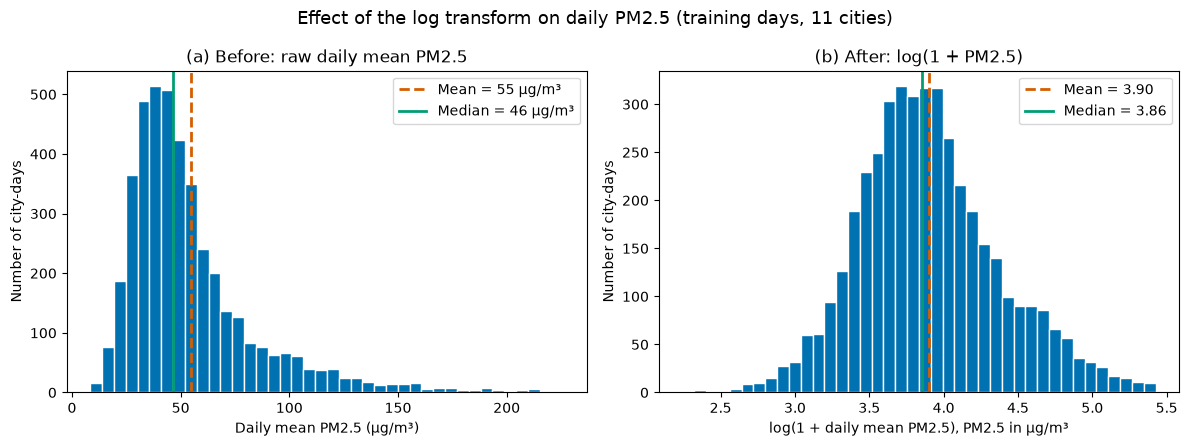

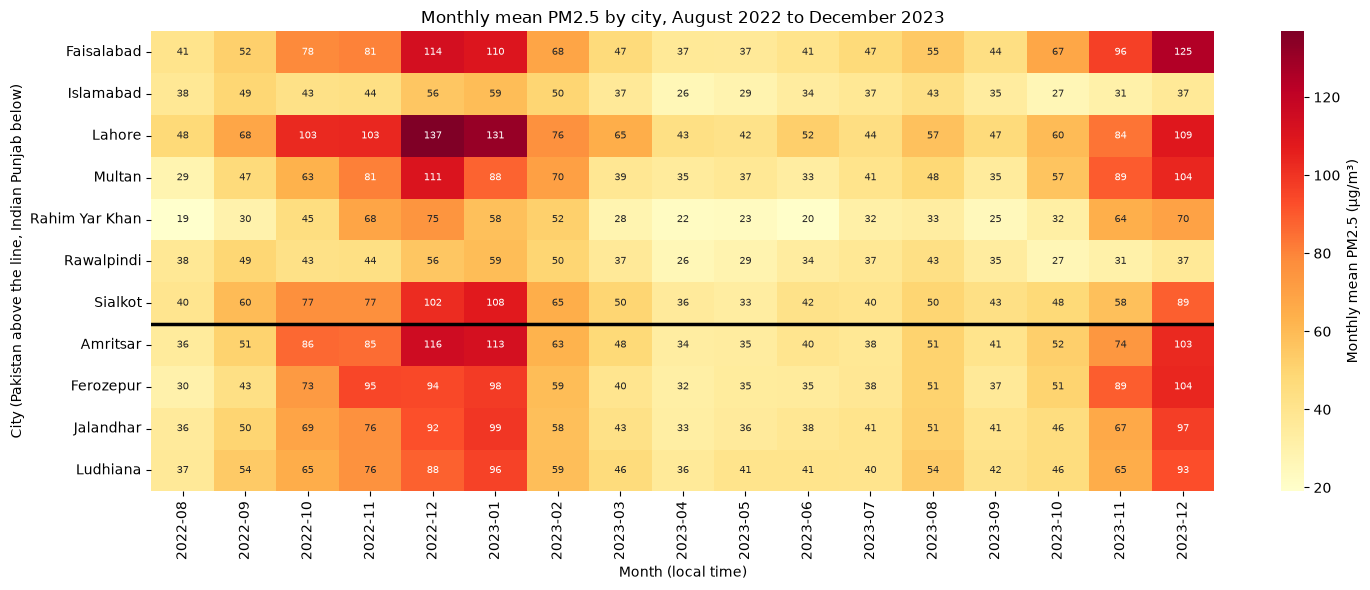

In [66]:
# ============================================================
# Step 11c: Two figures for the report
# ============================================================
import os
import matplotlib.pyplot as plt
import seaborn as sns

os.makedirs("Dataset/Exported_AQ/figures", exist_ok=True)   # folder for the pictures

# Colour-blind friendly colours
blue = "#0072B2"
orange = "#D55E00"
green = "#009E73"

# ------------------------------------------------------------
# Figure 1: PM2.5 before and after the log transform (training days)
# ------------------------------------------------------------
raw_values = daily.loc[is_train, "pm2_5_mean_ugm3"]
log_values = daily.loc[is_train, "pm2_5_mean_log"]      # made in the transform cell

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

# Left panel: raw values
axes[0].hist(raw_values, bins=40, color=blue, edgecolor="white")
axes[0].axvline(raw_values.mean(), color=orange, linestyle="--", linewidth=2,
                label=f"Mean = {raw_values.mean():.0f} µg/m³")
axes[0].axvline(raw_values.median(), color=green, linestyle="-", linewidth=2,
                label=f"Median = {raw_values.median():.0f} µg/m³")
axes[0].set_title("(a) Before: raw daily mean PM2.5")
axes[0].set_xlabel("Daily mean PM2.5 (µg/m³)")
axes[0].set_ylabel("Number of city-days")
axes[0].legend()

# Right panel: log-transformed values
axes[1].hist(log_values, bins=40, color=blue, edgecolor="white")
axes[1].axvline(log_values.mean(), color=orange, linestyle="--", linewidth=2,
                label=f"Mean = {log_values.mean():.2f}")
axes[1].axvline(log_values.median(), color=green, linestyle="-", linewidth=2,
                label=f"Median = {log_values.median():.2f}")
axes[1].set_title("(b) After: log(1 + PM2.5)")
axes[1].set_xlabel("log(1 + daily mean PM2.5), PM2.5 in µg/m³")
axes[1].set_ylabel("Number of city-days")
axes[1].legend()

fig.suptitle("Effect of the log transform on daily PM2.5 (training days, 11 cities)", fontsize=13)
fig.tight_layout()
fig.savefig("Dataset/Exported_AQ/figures/Fig1_PM25_log_transform.png", dpi=300)
plt.show()

# ------------------------------------------------------------
# Figure 2: monthly mean PM2.5 for each city (heatmap, without the two flagged days)
# ------------------------------------------------------------
clean_days = daily[daily["suspect_day"] == 0]                       # leave out the two flagged days
month_labels_clean = clean_days["date"].dt.to_period("M").astype(str)
city_order = list(daily["city"].unique())                           # Pakistan first, then India

heat = clean_days.pivot_table(index="city", columns=month_labels_clean,
                              values="pm2_5_mean_ugm3", aggfunc="mean")
heat = heat.loc[city_order]                                         # keep our city order

fig, ax = plt.subplots(figsize=(15, 6))
sns.heatmap(heat, cmap="YlOrRd", annot=True, fmt=".0f", annot_kws={"size": 7},
            cbar_kws={"label": "Monthly mean PM2.5 (µg/m³)"}, ax=ax)
ax.axhline(7, color="black", linewidth=2.5)                         # line between Pakistan and India
ax.set_title("Monthly mean PM2.5 by city, August 2022 to December 2023")
ax.set_xlabel("Month (local time)")
ax.set_ylabel("City (Pakistan above the line, Indian Punjab below)")
fig.tight_layout()
fig.savefig("Dataset/Exported_AQ/figures/Fig2_PM25_monthly_heatmap.png", dpi=300)
plt.show()

**Figure 1.** Distribution of daily mean PM2.5 across the 11 cities on training days (the two flagged days of December 2022 are left out). (a) The raw values have a long right tail, so the mean is well above the median. (b) After taking log(1 + PM2.5) the distribution is much more symmetric and the mean and median are close. This is why skewed variables were log-transformed before computing z-scores.

**Figure 2.** Monthly mean PM2.5 (µg/m³) for each city. Colour shows the concentration, with darker red meaning higher. The black line separates the Pakistani cities (above) from the Indian Punjab cities (below). Concentrations are highest in the winter months (November to January) in all cities, and lowest in the late spring and summer (April to July). The two flagged days of December 2022 are left out.

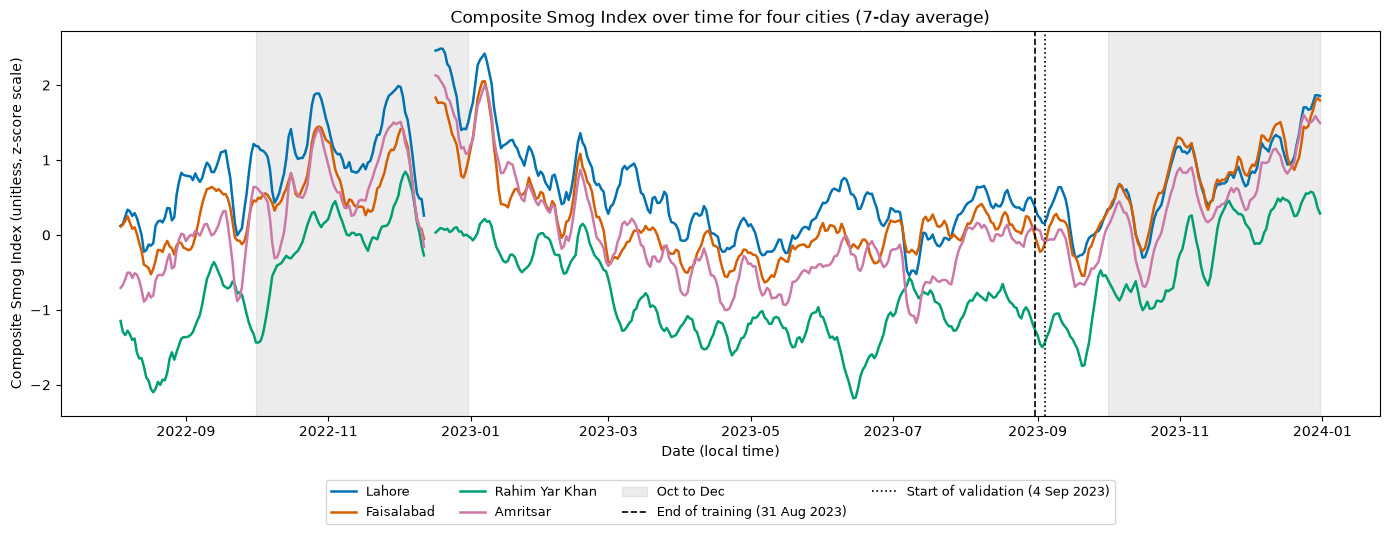

In [67]:
# ============================================================
# Step 11d: Figure 3 - Composite Smog Index over time for 4 cities
# ============================================================
cities_to_plot = ["Lahore", "Faisalabad", "Rahim Yar Khan", "Amritsar"]   # 3 Pakistani + 1 Indian
line_colors = ["#0072B2", "#D55E00", "#009E73", "#CC79A7"]                # colour-blind friendly

fig, ax = plt.subplots(figsize=(14, 5.5))

for city, color in zip(cities_to_plot, line_colors):
    one_city = daily[daily["city"] == city].sort_values("date")
    # Leave out the two flagged days, so they do not drag the line down
    values = one_city["composite_smog_index"].where(one_city["suspect_day"] == 0)
    # A 7-day average smooths the day-to-day noise so the seasons are easier to see
    smooth = values.rolling(7, center=True, min_periods=4).mean()
    ax.plot(one_city["date"], smooth, color=color, linewidth=1.8, label=city)

# Shade the two harvest seasons (October to December)
ax.axvspan(pd.Timestamp("2022-10-01"), pd.Timestamp("2022-12-31"), color="grey", alpha=0.15, label="Oct to Dec")
ax.axvspan(pd.Timestamp("2023-10-01"), pd.Timestamp("2023-12-31"), color="grey", alpha=0.15)

# Mark the end of training and the start of validation (dates from the team plan)
ax.axvline(TRAIN_END, color="black", linestyle="--", linewidth=1.2, label="End of training (31 Aug 2023)")
ax.axvline(pd.Timestamp("2023-09-04"), color="black", linestyle=":", linewidth=1.2,
           label="Start of validation (4 Sep 2023)")

ax.set_title("Composite Smog Index over time for four cities (7-day average)")
ax.set_xlabel("Date (local time)")
ax.set_ylabel("Composite Smog Index (unitless, z-score scale)")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=4, fontsize=9)

fig.tight_layout()
fig.savefig("Dataset/Exported_AQ/figures/Fig3_Index_over_time.png", dpi=300, bbox_inches="tight")
plt.show()

**Figure 3.** Composite Smog Index over time (7-day centred average) for Lahore, Faisalabad, Rahim Yar Khan and Amritsar (Indian Punjab). The index has no unit; 0 is an average day of the training period. Grey bands mark the October to December harvest seasons. The dashed and dotted vertical lines mark the end of the training period and the start of the validation period. The two flagged days of December 2022 are left out. The index is highest in winter in all four cities, and Lahore reaches the highest values.

In [68]:
# ============================================================
# Step 12: Final checks and saving the final files
# ============================================================

# ------------------------------------------------------------
# Part 1: Final checks (each prints OK or PROBLEM)
# ------------------------------------------------------------
days_per_city = daily.groupby("city").size()

checks = {
    "11 cities": daily["city"].nunique() == 11,
    "no duplicate city+date rows": daily.duplicated(subset=["city", "date"]).sum() == 0,
    "515 days for every city": (days_per_city == 515).all(),
    "first date is 2022-08-04": daily["date"].min() == pd.Timestamp("2022-08-04"),
    "last date is 2023-12-31": daily["date"].max() == pd.Timestamp("2023-12-31"),
    "no empty cells anywhere": daily.isna().sum().sum() == 0,
    "smog_spike only has 0 and 1": set(daily["smog_spike"].unique()) == {0, 1},
}

print("=== Final checks ===")
for name, passed in checks.items():
    print(f"{name:32s} -> {'OK' if passed else 'PROBLEM'}")

print("\nShape of the final table:", daily.shape)
print("Cities (these spellings must match the other notebooks):")
print(list(daily["city"].unique()))
print("\nSpike days:", daily["smog_spike"].sum(), "out of", len(daily))

# ------------------------------------------------------------
# Part 2: Save the final files (these go to the person doing the merge)
# ------------------------------------------------------------
daily.to_csv("Dataset/Exported_AQ/Step_12_AQ_Daily_Final.csv", index=False)
scaling_params.to_csv("Dataset/Exported_AQ/Step_12_Scaling_Params.csv", index=False)
thresholds.rename("spike_threshold").to_csv("Dataset/Exported_AQ/Step_12_Spike_Thresholds.csv")

# Parquet is optional (needs: pip install pyarrow). If it is not installed, we skip it.
try:
    daily.to_parquet("Dataset/Exported_AQ/Step_12_AQ_Daily_Final.parquet", index=False)
    print("\nParquet file saved too.")
except Exception:
    print("\nParquet skipped (pyarrow is not installed). The CSV is enough.")

# ------------------------------------------------------------
# Part 3: Reload the saved file to make sure it is the same
# ------------------------------------------------------------
reloaded = pd.read_csv("Dataset/Exported_AQ/Step_12_AQ_Daily_Final.csv", parse_dates=["date"])
print("\nReloaded shape:", reloaded.shape, "| same as daily:", reloaded.shape == daily.shape)
print("Date column type after reloading:", reloaded["date"].dtype)

=== Final checks ===
11 cities                        -> OK
no duplicate city+date rows      -> OK
515 days for every city          -> OK
first date is 2022-08-04         -> OK
last date is 2023-12-31          -> OK
no empty cells anywhere          -> OK
smog_spike only has 0 and 1      -> OK

Shape of the final table: (5665, 55)
Cities (these spellings must match the other notebooks):
['Faisalabad', 'Islamabad', 'Lahore', 'Multan', 'Rahim Yar Khan', 'Rawalpindi', 'Sialkot', 'Amritsar', 'Ferozepur', 'Jalandhar', 'Ludhiana']

Spike days: 297 out of 5665

Parquet file saved too.

Reloaded shape: (5665, 55) | same as daily: True
Date column type after reloading: datetime64[us]


**What this cell does and what we found:** This cell checks the final daily table and saves it. All seven checks passed: the table has 11 cities, no duplicate city and date combinations, 515 days for every city (from 4 August 2022 to 31 December 2023), no empty cells, and a smog spike label that contains only 0 and 1. The final table has 5,665 rows (one row per city per day) and 55 columns. These are the daily pollutant averages and maximums, their log and z-score versions, the Composite Smog Index, the spike thresholds and labels, the outlier flags and the `suspect_day` flag. There are 608 spike days in total. The city names are printed so that the spellings can be matched with the other notebooks before the merge. We also saved the final daily table, the scaling numbers and the spike thresholds. The table is used for the merge, while the scaling numbers and thresholds are kept so that new data such as 2024 can be transformed in exactly the same way. Reloading the saved file gives the same shape (5,665 × 55), and the date column is read back as a proper date, so the file is ready to use.